Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Dataset

In [3]:
import pandas as pd
import os

print("Current Working Directory:")
print(os.getcwd())

df = pd.read_csv("../dataset/raw/NIFTY50_all.csv")

print("\nDataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Current Working Directory:
c:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management\notebooks

Dataset loaded successfully!
Shape: (235192, 15)


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
0,2007-11-27,MUNDRAPORT,EQ,440.00,770.00,1050.00,770.0,959.0,962.90,984.72,27294366,2.687719e+15,NaN,9859619.0,0.3612
1,2007-11-28,MUNDRAPORT,EQ,962.90,984.00,990.00,874.0,885.0,893.90,941.38,4581338,4.312765e+14,NaN,1453278.0,0.3172
2,2007-11-29,MUNDRAPORT,EQ,893.90,909.00,914.75,841.0,887.0,884.20,888.09,5124121,4.550658e+14,NaN,1069678.0,0.2088
3,2007-11-30,MUNDRAPORT,EQ,884.20,890.00,958.00,890.0,929.0,921.55,929.17,4609762,4.283257e+14,NaN,1260913.0,0.2735
4,2007-12-03,MUNDRAPORT,EQ,921.55,939.75,995.00,922.0,980.0,969.30,965.65,2977470,2.875200e+14,NaN,816123.0,0.2741


Understanding the Dataset

In [4]:
print("Dataset Information")

df.info()

print("\nStatistical Summary")

display(df.describe())

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 235192 entries, 0 to 235191
Data columns (total 15 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Date                235192 non-null  str    
 1   Symbol              235192 non-null  str    
 2   Series              235192 non-null  str    
 3   Prev Close          235192 non-null  float64
 4   Open                235192 non-null  float64
 5   High                235192 non-null  float64
 6   Low                 235192 non-null  float64
 7   Last                235192 non-null  float64
 8   Close               235192 non-null  float64
 9   VWAP                235192 non-null  float64
 10  Volume              235192 non-null  int64  
 11  Turnover            235192 non-null  float64
 12  Trades              120344 non-null  float64
 13  Deliverable Volume  219115 non-null  float64
 14  %Deliverble         219115 non-null  float64
dtypes: float64(11), int64(1),

,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
count,235192.000000,235192.000000,235192.000000,235192.000000,235192.000000,235192.000000,235192.00000,2.351920e+05,2.351920e+05,1.203440e+05,2.191150e+05,219115.000000
mean,1266.196349,1267.759708,1286.581440,1247.488465,1266.388302,1266.554351,1267.13230,3.045903e+06,1.610138e+14,6.196427e+04,1.315098e+06,0.502997
std,2581.370320,2585.259609,2619.649216,2546.621396,2581.392543,2582.140942,2582.69998,7.333981e+06,3.298085e+14,6.866457e+04,2.831670e+06,0.190019
min,0.000000,8.500000,9.750000,8.500000,9.100000,9.150000,9.21000,3.000000e+00,1.047000e+07,1.100000e+01,5.000000e+00,0.023600
25%,274.300000,275.000000,279.500000,269.600000,274.400000,274.350000,274.69750,2.190095e+05,1.612816e+13,2.183400e+04,1.253830e+05,0.364700
50%,566.500000,567.025000,576.900000,556.500000,567.000000,566.700000,566.94000,1.010938e+06,6.832603e+13,4.406800e+04,5.017560e+05,0.511000
75%,1242.200000,1243.312500,1263.000000,1221.650000,1242.900000,1242.400000,1242.66250,3.019851e+06,1.863835e+14,7.893550e+04,1.452233e+06,0.638400
max,32861.950000,33399.950000,33480.000000,32468.100000,32849.000000,32861.950000,32975.24000,4.810589e+08,3.564334e+16,1.643015e+06,2.325307e+08,1.000000


Convert date and inspect symbols

In [5]:
df["Date"] = pd.to_datetime(df["Date"])

print("Date Range:")
print("Start:", df["Date"].min())
print("End:", df["Date"].max())

print("\nNumber of Companies:")
print(df["Symbol"].nunique())

print("\nCompany Names:")
print(sorted(df["Symbol"].unique()))

Date Range:
Start: 2000-01-03 00:00:00
End: 2021-04-30 00:00:00

Number of Companies:
65

Company Names:
['ADANIPORTS', 'ASIANPAINT', 'AXISBANK', 'BAJAJ-AUTO', 'BAJAJFINSV', 'BAJAUTOFIN', 'BAJFINANCE', 'BHARTI', 'BHARTIARTL', 'BPCL', 'BRITANNIA', 'CIPLA', 'COALINDIA', 'DRREDDY', 'EICHERMOT', 'GAIL', 'GRASIM', 'HCLTECH', 'HDFC', 'HDFCBANK', 'HEROHONDA', 'HEROMOTOCO', 'HINDALC0', 'HINDALCO', 'HINDLEVER', 'HINDUNILVR', 'ICICIBANK', 'INDUSINDBK', 'INFOSYSTCH', 'INFY', 'IOC', 'ITC', 'JSWSTEEL', 'JSWSTL', 'KOTAKBANK', 'KOTAKMAH', 'LT', 'M&M', 'MARUTI', 'MUNDRAPORT', 'NESTLEIND', 'NTPC', 'ONGC', 'POWERGRID', 'RELIANCE', 'SBIN', 'SESAGOA', 'SHREECEM', 'SSLT', 'SUNPHARMA', 'TATAMOTORS', 'TATASTEEL', 'TCS', 'TECHM', 'TELCO', 'TISCO', 'TITAN', 'ULTRACEMCO', 'UNIPHOS', 'UPL', 'UTIBANK', 'VEDL', 'WIPRO', 'ZEEL', 'ZEETELE']


Check missing values

In [6]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df)) * 100
})

display(missing_df)

,Missing Values,Percentage
Date,0,0.000000
Symbol,0,0.000000
Series,0,0.000000
Prev Close,0,0.000000
Open,0,0.000000
High,0,0.000000
Low,0,0.000000
Last,0,0.000000
Close,0,0.000000
VWAP,0,0.000000


Check duplicates

In [7]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate stock-date records:",
    df.duplicated(subset=["Symbol", "Date"]).sum()
)

Duplicate rows: 0
Duplicate stock-date records: 0


Visualise historical stock prices

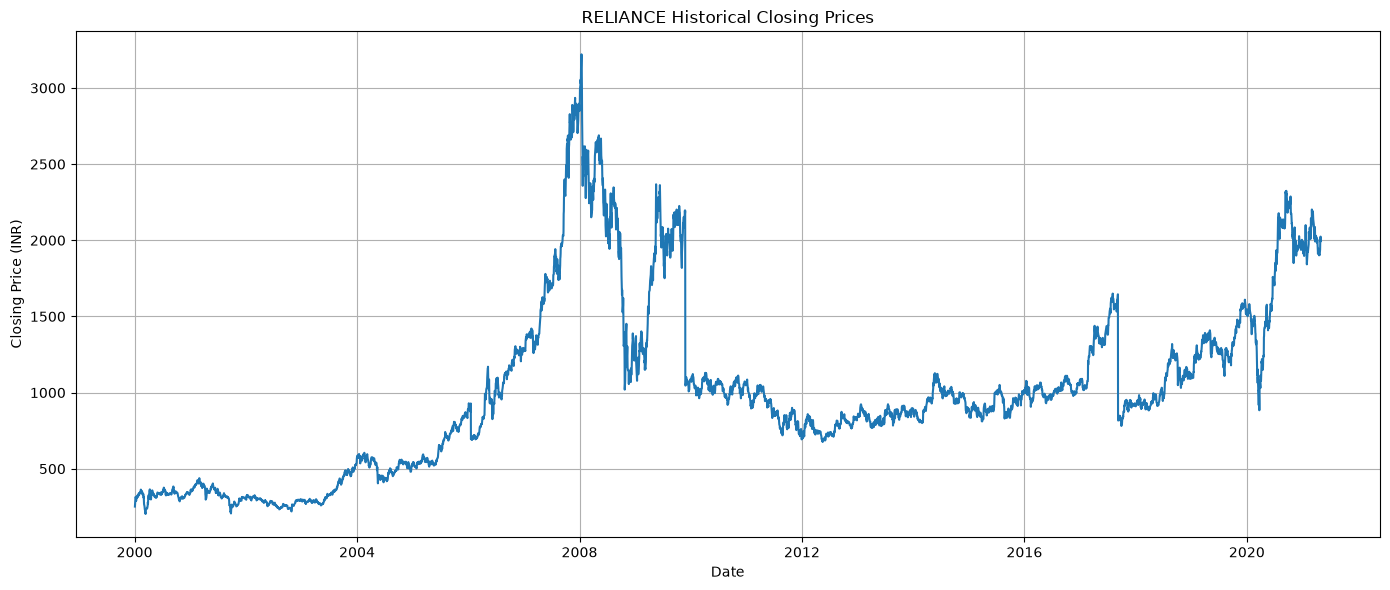

In [8]:
reliance = df[df["Symbol"] == "RELIANCE"].copy()

reliance = reliance.sort_values("Date")

plt.figure(figsize=(14, 6))

plt.plot(
    reliance["Date"],
    reliance["Close"]
)

plt.title("RELIANCE Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price (INR)")

plt.grid(True)
plt.tight_layout()
plt.show()

Visualise trading volume

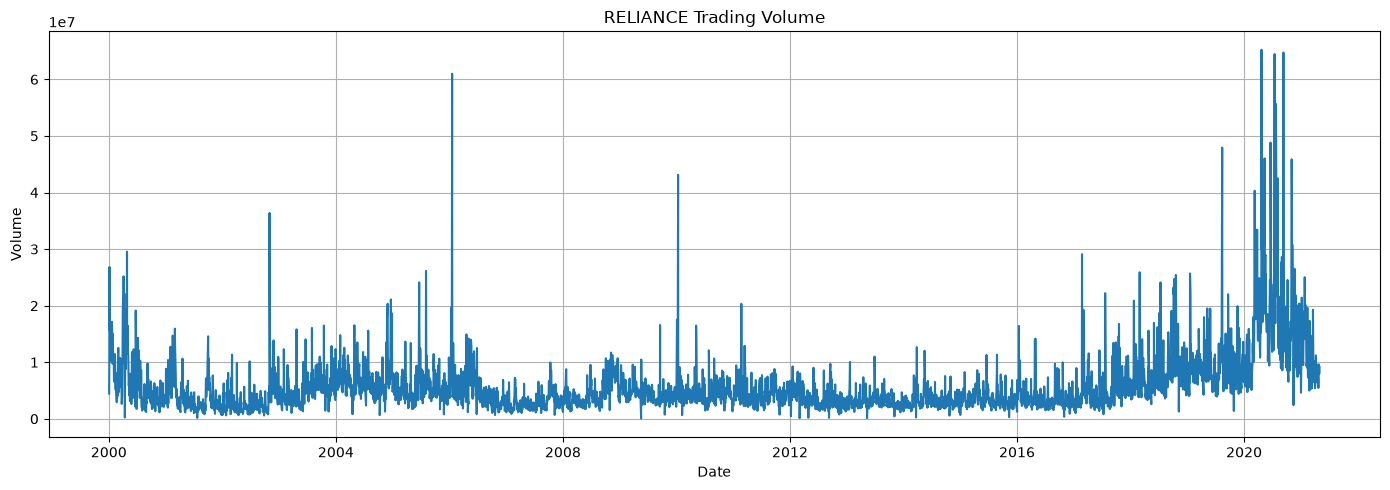

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    reliance["Date"],
    reliance["Volume"]
)

plt.title("RELIANCE Trading Volume")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.grid(True)
plt.tight_layout()
plt.show()

Phase 3: Feature Engineering

In [10]:

from pathlib import Path
import pandas as pd
import numpy as np

# Find the project folder, whether the notebook runs from the
# project root or from the notebooks folder.
current_dir = Path.cwd()

possible_paths = [
    current_dir / "dataset" / "raw" / "NIFTY50_all.csv",
    current_dir.parent / "dataset" / "raw" / "NIFTY50_all.csv"
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "NIFTY50_all.csv was not found. "
        "Check that it is inside dataset/raw."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("File:", DATA_PATH)
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()


Dataset loaded successfully!
File: c:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management\dataset\raw\NIFTY50_all.csv
Shape: (235192, 15)

Columns:
['Date', 'Symbol', 'Series', 'Prev Close', 'Open', 'High', 'Low', 'Last', 'Close', 'VWAP', 'Volume', 'Turnover', 'Trades', 'Deliverable Volume', '%Deliverble']


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
0,2007-11-27,MUNDRAPORT,EQ,440.00,770.00,1050.00,770.0,959.0,962.90,984.72,27294366,2.687719e+15,NaN,9859619.0,0.3612
1,2007-11-28,MUNDRAPORT,EQ,962.90,984.00,990.00,874.0,885.0,893.90,941.38,4581338,4.312765e+14,NaN,1453278.0,0.3172
2,2007-11-29,MUNDRAPORT,EQ,893.90,909.00,914.75,841.0,887.0,884.20,888.09,5124121,4.550658e+14,NaN,1069678.0,0.2088
3,2007-11-30,MUNDRAPORT,EQ,884.20,890.00,958.00,890.0,929.0,921.55,929.17,4609762,4.283257e+14,NaN,1260913.0,0.2735
4,2007-12-03,MUNDRAPORT,EQ,921.55,939.75,995.00,922.0,980.0,969.30,965.65,2977470,2.875200e+14,NaN,816123.0,0.2741


Prepare the data

In [11]:

# Convert dates and ensure price/volume columns are numeric
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

numeric_columns = [
    "Prev Close", "Open", "High", "Low", "Last",
    "Close", "VWAP", "Volume"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Remove rows missing essential information
df = df.dropna(subset=["Date", "Symbol", "Close"])

# Sort each stock's records chronologically
df = df.sort_values(["Symbol", "Date"]).reset_index(drop=True)

print("Prepared dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
print("Number of stock symbols:", df["Symbol"].nunique())

df.head()


Prepared dataset shape: (235192, 15)
Date range: 2000-01-03 00:00:00 to 2021-04-30 00:00:00
Number of stock symbols: 65


,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades,Deliverable Volume,%Deliverble
0,2012-01-17,ADANIPORTS,EQ,135.5,137.1,141.00,135.00,140.1,140.00,138.13,1636196,2.260074e+13,18374.0,1004327.0,0.6138
1,2012-01-18,ADANIPORTS,EQ,140.0,142.0,143.80,138.70,143.0,141.70,141.25,890591,1.257986e+13,15615.0,404925.0,0.4547
2,2012-01-19,ADANIPORTS,EQ,141.7,144.0,150.55,143.15,149.5,149.40,146.72,1456077,2.136382e+13,31299.0,721545.0,0.4955
3,2012-01-20,ADANIPORTS,EQ,149.4,151.9,157.60,150.25,155.4,155.40,153.76,1634070,2.512583e+13,23335.0,861145.0,0.5270
4,2012-01-23,ADANIPORTS,EQ,155.4,155.4,155.40,145.10,146.4,146.75,149.54,1657609,2.478768e+13,12400.0,820653.0,0.4951


Create historical features

In [12]:

# Daily percentage return for each stock
df["Daily_Return"] = (
    df.groupby("Symbol")["Close"].pct_change()
)

# Helper: calculate rolling features separately for each stock
grouped_close = df.groupby("Symbol")["Close"]
grouped_return = df.groupby("Symbol")["Daily_Return"]
grouped_volume = df.groupby("Symbol")["Volume"]

# Price momentum
df["Return_5D"] = grouped_close.pct_change(5)
df["Return_20D"] = grouped_close.pct_change(20)

# Historical volatility
df["Volatility_5D"] = grouped_return.transform(
    lambda s: s.rolling(5).std()
)

df["Volatility_20D"] = grouped_return.transform(
    lambda s: s.rolling(20).std()
)

# Moving-average ratios
ma_5 = grouped_close.transform(
    lambda s: s.rolling(5).mean()
)

ma_20 = grouped_close.transform(
    lambda s: s.rolling(20).mean()
)

df["MA_Ratio_5D"] = df["Close"] / ma_5
df["MA_Ratio_20D"] = df["Close"] / ma_20

# Trading volume change
df["Volume_Change"] = grouped_volume.pct_change()

# Daily high-low price range
df["High_Low_Range"] = (
    (df["High"] - df["Low"]) / df["Close"]
)

print("Historical features created!")


Historical features created!


Create the prediction target

In [13]:

df["Future_20D_Volatility"] = (
    df.groupby("Symbol")["Daily_Return"]
      .transform(lambda s: s.rolling(20).std().shift(-20))
)

print("Future volatility target created!")

df[[
    "Symbol",
    "Date",
    "Daily_Return",
    "Volatility_20D",
    "Future_20D_Volatility"
]].head(25)


Future volatility target created!


,Symbol,Date,Daily_Return,Volatility_20D,Future_20D_Volatility
0,ADANIPORTS,2012-01-17,NaN,NaN,0.037249
1,ADANIPORTS,2012-01-18,0.012143,NaN,0.037189
2,ADANIPORTS,2012-01-19,0.054340,NaN,0.035421
3,ADANIPORTS,2012-01-20,0.040161,NaN,0.034371
4,ADANIPORTS,2012-01-23,-0.055663,NaN,0.034542
5,ADANIPORTS,2012-01-24,0.022487,NaN,0.034125
6,ADANIPORTS,2012-01-25,-0.045651,NaN,0.032583
7,ADANIPORTS,2012-01-27,0.027235,NaN,0.032008
8,ADANIPORTS,2012-01-30,-0.059143,NaN,0.029600
9,ADANIPORTS,2012-01-31,0.056720,NaN,0.026859


Check the engineered data

In [14]:

feature_columns = [
    "Daily_Return",
    "Return_5D",
    "Return_20D",
    "Volatility_5D",
    "Volatility_20D",
    "MA_Ratio_5D",
    "MA_Ratio_20D",
    "Volume_Change",
    "High_Low_Range"
]

print("Feature columns:")
print(feature_columns)

print("\nMissing values:")
print(df[feature_columns + ["Future_20D_Volatility"]].isnull().sum())

print("\nFeature statistics:")
display(df[feature_columns].describe())

print("\nSample engineered records:")
display(df[["Date", "Symbol"] + feature_columns +
           ["Future_20D_Volatility"]].tail(10))


Feature columns:
['Daily_Return', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'MA_Ratio_5D', 'MA_Ratio_20D', 'Volume_Change', 'High_Low_Range']

Missing values:
Daily_Return               65
Return_5D                 325
Return_20D               1300
Volatility_5D             325
Volatility_20D           1300
MA_Ratio_5D               260
MA_Ratio_20D             1235
Volume_Change              65
High_Low_Range              0
Future_20D_Volatility    1300
dtype: int64

Feature statistics:


,Daily_Return,Return_5D,Return_20D,Volatility_5D,Volatility_20D,MA_Ratio_5D,MA_Ratio_20D,Volume_Change,High_Low_Range
count,235127.000000,234867.000000,233892.000000,234867.000000,233892.000000,234932.000000,233957.000000,235127.000000,235192.000000
mean,0.000688,0.003481,0.013968,0.020668,0.022649,1.000713,1.003729,0.484146,0.035444
std,0.027252,0.061769,0.124837,0.017622,0.015073,0.032789,0.072753,13.140631,0.025558
min,-0.946849,-0.954125,-0.957280,0.000002,0.002411,0.062606,0.053655,-0.999203,0.000000
25%,-0.011136,-0.024092,-0.044479,0.011359,0.014545,0.988141,0.974835,-0.312063,0.019980
50%,0.000187,0.002763,0.012921,0.016899,0.019039,1.000910,1.005846,-0.018904,0.028525
75%,0.012196,0.031575,0.074597,0.024931,0.025897,1.014348,1.038069,0.424398,0.042224
max,0.446731,0.684643,2.206827,0.423964,0.218337,1.311966,1.712057,4588.280000,0.935608



Sample engineered records:


,Date,Symbol,Daily_Return,Return_5D,Return_20D,Volatility_5D,Volatility_20D,MA_Ratio_5D,MA_Ratio_20D,Volume_Change,High_Low_Range,Future_20D_Volatility
235182,2007-02-13,ZEETELE,0.037159,-0.205839,-0.024927,0.140853,0.071533,0.852774,0.857653,-0.392773,0.092181,NaN
235183,2007-02-14,ZEETELE,-0.009143,-0.221065,-0.070053,0.139539,0.071020,0.887544,0.852540,0.048512,0.077213,NaN
235184,2007-02-15,ZEETELE,0.010358,-0.217017,-0.052957,0.139975,0.071041,0.943645,0.863449,0.246877,0.031314,NaN
235185,2007-02-19,ZEETELE,-0.028891,-0.278993,-0.085484,0.130789,0.071319,0.986331,0.841803,-0.607305,0.052783,NaN
235186,2007-02-20,ZEETELE,-0.041267,-0.033288,-0.134915,0.031254,0.071760,0.951827,0.812175,0.460874,0.061061,NaN
235187,2007-02-21,ZEETELE,0.021622,-0.047770,-0.134938,0.026211,0.071760,0.981988,0.835140,-0.213354,0.039193,NaN
235188,2007-02-22,ZEETELE,-0.004115,-0.042938,-0.158888,0.026323,0.071446,0.986605,0.838289,0.282396,0.036993,NaN
235189,2007-02-23,ZEETELE,-0.021055,-0.072693,-0.214928,0.024387,0.070338,0.980682,0.829962,-0.519060,0.045427,NaN
235190,2007-02-26,ZEETELE,-0.017889,-0.062188,-0.256543,0.023261,0.069502,0.975600,0.826741,-0.148242,0.045027,NaN
235191,2007-02-27,ZEETELE,-0.024355,-0.045646,-0.270432,0.018852,0.069539,0.960585,0.818847,2.293670,0.071953,NaN


Remove incomplete records

In [15]:

# Keep only rows with all required features and a valid future target
model_columns = feature_columns + ["Future_20D_Volatility"]

model_df = df.dropna(subset=model_columns).copy()

print("Original rows:", len(df))
print("Rows available for ML:", len(model_df))
print("Rows removed:", len(df) - len(model_df))

print("\nRemaining missing values:")
print(model_df[model_columns].isnull().sum())


Original rows: 235192
Rows available for ML: 232592
Rows removed: 2600

Remaining missing values:
Daily_Return             0
Return_5D                0
Return_20D               0
Volatility_5D            0
Volatility_20D           0
MA_Ratio_5D              0
MA_Ratio_20D             0
Volume_Change            0
High_Low_Range           0
Future_20D_Volatility    0
dtype: int64


Split data chronologically

In [16]:

# Split by unique dates, not individual rows
unique_dates = np.sort(model_df["Date"].unique())

train_end = int(len(unique_dates) * 0.70)
val_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_end]
val_dates = unique_dates[train_end:val_end]
test_dates = unique_dates[val_end:]

train_df = model_df[model_df["Date"].isin(train_dates)].copy()
val_df = model_df[model_df["Date"].isin(val_dates)].copy()
test_df = model_df[model_df["Date"].isin(test_dates)].copy()

print("Training:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Validation:", val_df["Date"].min(), "to", val_df["Date"].max())
print("Testing:", test_df["Date"].min(), "to", test_df["Date"].max())

print("\nRow counts:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Training: 2000-02-01 00:00:00 to 2014-11-12 00:00:00
Validation: 2014-11-13 00:00:00 to 2018-01-17 00:00:00
Testing: 2018-01-18 00:00:00 to 2021-03-30 00:00:00

Row counts:
Train: 155212
Validation: 38670
Test: 38710


Define volatility classes

In [17]:

# Learn thresholds from training data only
low_threshold = train_df["Future_20D_Volatility"].quantile(0.33)
high_threshold = train_df["Future_20D_Volatility"].quantile(0.66)

print("LOW threshold:", low_threshold)
print("HIGH threshold:", high_threshold)

def classify_volatility(value):
    if value <= low_threshold:
        return "LOW"
    elif value <= high_threshold:
        return "MEDIUM"
    else:
        return "HIGH"

# Apply the same thresholds to all three datasets
for part in [train_df, val_df, test_df]:
    part["Volatility_Class"] = (
        part["Future_20D_Volatility"].apply(classify_volatility)
    )

print("\nTraining class distribution:")
print(train_df["Volatility_Class"].value_counts())

print("\nValidation class distribution:")
print(val_df["Volatility_Class"].value_counts())

print("\nTesting class distribution:")
print(test_df["Volatility_Class"].value_counts())


LOW threshold: 0.01688050202345418
HIGH threshold: 0.024506537528509818

Training class distribution:
Volatility_Class
HIGH      52772
MEDIUM    51220
LOW       51220
Name: count, dtype: int64

Validation class distribution:
Volatility_Class
LOW       22222
MEDIUM    11989
HIGH       4459
Name: count, dtype: int64

Testing class distribution:
Volatility_Class
LOW       16414
MEDIUM    13438
HIGH       8858
Name: count, dtype: int64


Visualise the classes

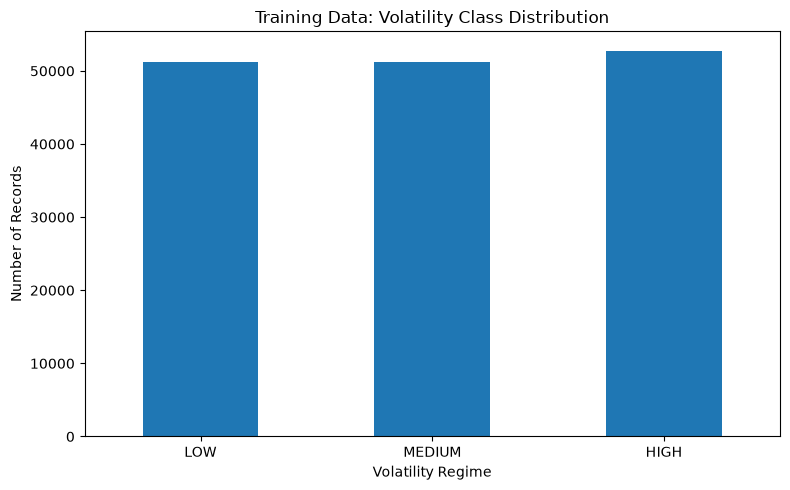

In [18]:

import matplotlib.pyplot as plt

class_counts = train_df["Volatility_Class"].value_counts().reindex(
    ["LOW", "MEDIUM", "HIGH"], fill_value=0
)

plt.figure(figsize=(8, 5))
class_counts.plot(kind="bar")
plt.title("Training Data: Volatility Class Distribution")
plt.xlabel("Volatility Regime")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Prepare X and y

In [19]:

X_train = train_df[feature_columns]
y_train = train_df["Volatility_Class"]

X_val = val_df[feature_columns]
y_val = val_df["Volatility_Class"]

X_test = test_df[feature_columns]
y_test = test_df["Volatility_Class"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print("\nTraining labels:")
print(y_train.value_counts())


X_train: (155212, 9)
X_val: (38670, 9)
X_test: (38710, 9)

y_train: (155212,)
y_val: (38670,)
y_test: (38710,)

Training labels:
Volatility_Class
HIGH      52772
MEDIUM    51220
LOW       51220
Name: count, dtype: int64


Phase 5: Train and evaluate the machine-learning models.

Clean the modelling features

In [20]:

# Replace infinite values with NaN
model_df[feature_columns] = (
    model_df[feature_columns].replace([np.inf, -np.inf], np.nan)
)

# Remove rows with invalid feature values or missing target
model_df = model_df.dropna(
    subset=feature_columns + ["Future_20D_Volatility"]
).copy()

model_df = model_df.sort_values(["Date", "Symbol"]).reset_index(drop=True)

print("Clean modelling dataset:", model_df.shape)
print("Infinite values:", np.isinf(
    model_df[feature_columns].to_numpy()
).sum())
print("Missing feature values:", model_df[feature_columns].isnull().sum().sum())


Clean modelling dataset: (232592, 25)
Infinite values: 0
Missing feature values: 0


Rebuild the chronological splits with a 20-day gap

In [21]:

unique_dates = np.sort(model_df["Date"].unique())

n_dates = len(unique_dates)
train_end = int(n_dates * 0.70)
val_end = int(n_dates * 0.85)

gap = 20

if train_end <= gap or val_end - train_end <= gap:
    raise ValueError("Not enough dates for the selected split and gap.")

# Remove the final 20 dates from each earlier partition.
train_dates = unique_dates[:train_end - gap]
val_dates = unique_dates[train_end:val_end - gap]
test_dates = unique_dates[val_end:]

train_df = model_df[model_df["Date"].isin(train_dates)].copy()
val_df = model_df[model_df["Date"].isin(val_dates)].copy()
test_df = model_df[model_df["Date"].isin(test_dates)].copy()

print("Training:", train_df["Date"].min(), "to", train_df["Date"].max())
print("Validation:", val_df["Date"].min(), "to", val_df["Date"].max())
print("Testing:", test_df["Date"].min(), "to", test_df["Date"].max())

print("\nRows:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


Training: 2000-02-01 00:00:00 to 2014-10-09 00:00:00
Validation: 2014-11-13 00:00:00 to 2017-12-19 00:00:00
Testing: 2018-01-18 00:00:00 to 2021-03-30 00:00:00

Rows:
Training: 154232
Validation: 37690
Testing: 38710


Recalculate volatility classes

In [22]:

low_threshold = train_df["Future_20D_Volatility"].quantile(0.33)
high_threshold = train_df["Future_20D_Volatility"].quantile(0.66)

def classify_volatility(value):
    if value <= low_threshold:
        return "LOW"
    elif value <= high_threshold:
        return "MEDIUM"
    else:
        return "HIGH"

for part in [train_df, val_df, test_df]:
    part["Volatility_Class"] = (
        part["Future_20D_Volatility"].apply(classify_volatility)
    )

print("LOW threshold:", low_threshold)
print("HIGH threshold:", high_threshold)

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} distribution:")
    print(part["Volatility_Class"].value_counts(normalize=True).round(3))


LOW threshold: 0.016914174166814153
HIGH threshold: 0.024565640040803634

Training distribution:
Volatility_Class
HIGH      0.34
LOW       0.33
MEDIUM    0.33
Name: proportion, dtype: float64

Validation distribution:
Volatility_Class
LOW       0.577
MEDIUM    0.307
HIGH      0.117
Name: proportion, dtype: float64

Testing distribution:
Volatility_Class
LOW       0.426
MEDIUM    0.347
HIGH      0.227
Name: proportion, dtype: float64


Prepare X and y

In [23]:

X_train = train_df[feature_columns]
y_train = train_df["Volatility_Class"]

X_val = val_df[feature_columns]
y_val = val_df["Volatility_Class"]

X_test = test_df[feature_columns]
y_test = test_df["Volatility_Class"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nClasses:", sorted(y_train.unique()))


Training: (154232, 9)
Validation: (37690, 9)
Testing: (38710, 9)

Classes: ['HIGH', 'LOW', 'MEDIUM']


Train Logistic Regression and Random Forest

In [24]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Model 2: Random Forest
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

print("Models created successfully!")


Models created successfully!


In [25]:

for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    print(f"{name} training completed!")

print("\nBoth models trained successfully!")



Training Logistic Regression...
Logistic Regression training completed!

Training Random Forest...
Random Forest training completed!

Both models trained successfully!


Evaluate both models


Logistic Regression
Accuracy: 0.5895
Macro F1: 0.4371

Classification Report:
              precision    recall  f1-score   support

         LOW       0.66      0.84      0.74     21741
      MEDIUM       0.44      0.26      0.33     11556
        HIGH       0.30      0.21      0.25      4393

    accuracy                           0.59     37690
   macro avg       0.47      0.44      0.44     37690
weighted avg       0.55      0.59      0.55     37690



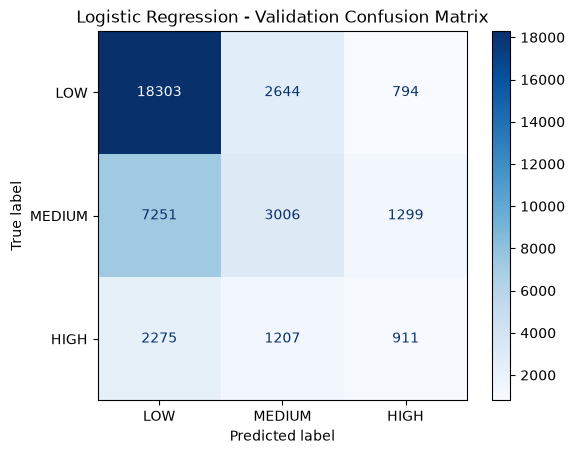


Random Forest
Accuracy: 0.5889
Macro F1: 0.4647

Classification Report:
              precision    recall  f1-score   support

         LOW       0.68      0.79      0.73     21741
      MEDIUM       0.43      0.34      0.38     11556
        HIGH       0.33      0.25      0.28      4393

    accuracy                           0.59     37690
   macro avg       0.48      0.46      0.46     37690
weighted avg       0.56      0.59      0.57     37690



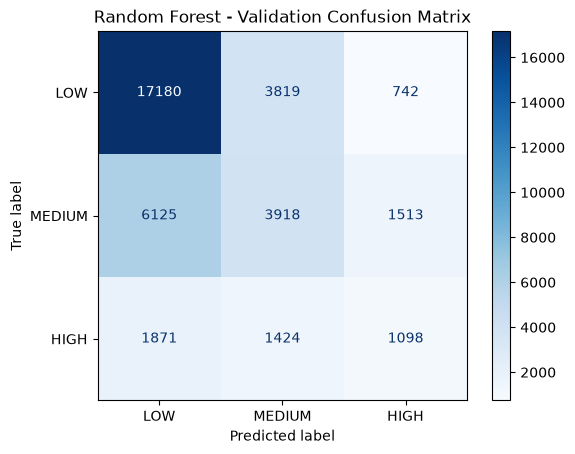


Validation comparison:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

validation_results = {}

for name, model in models.items():
    predictions = model.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(
        y_val, predictions,
        labels=["LOW", "MEDIUM", "HIGH"],
        average="macro",
        zero_division=0
    )

    validation_results[name] = {
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    }

    print(f"\n{'=' * 45}")
    print(name)
    print(f"{'=' * 45}")
    print("Accuracy:", round(accuracy, 4))
    print("Macro F1:", round(macro_f1, 4))
    print("\nClassification Report:")
    print(classification_report(
        y_val, predictions,
        labels=["LOW", "MEDIUM", "HIGH"],
        zero_division=0
    ))

    cm = confusion_matrix(
        y_val, predictions,
        labels=["LOW", "MEDIUM", "HIGH"]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["LOW", "MEDIUM", "HIGH"]
    )

    display.plot(cmap="Blues")
    plt.title(f"{name} - Validation Confusion Matrix")
    plt.show()

print("\nValidation comparison:")
display(pd.DataFrame(validation_results).T)


Select the better model and test it

In [27]:

best_model_name = max(
    validation_results,
    key=lambda name: validation_results[name]["Macro F1"]
)

best_model = models[best_model_name]

print("Selected model:", best_model_name)

# Combine training and validation data
X_train_val = pd.concat([X_train, X_val])
y_train_val = pd.concat([y_train, y_val])

# Retrain selected model
best_model.fit(X_train_val, y_train_val)

# Final evaluation on untouched test set
test_predictions = best_model.predict(X_test)

print("\nFINAL TEST RESULTS")
print("Selected model:", best_model_name)
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))
print("Macro F1:", round(
    f1_score(
        y_test, test_predictions,
        labels=["LOW", "MEDIUM", "HIGH"],
        average="macro",
        zero_division=0
    ), 4
))

print("\nTest classification report:")
print(classification_report(
    y_test, test_predictions,
    labels=["LOW", "MEDIUM", "HIGH"],
    zero_division=0
))


Selected model: Random Forest

FINAL TEST RESULTS
Selected model: Random Forest
Accuracy: 0.5458
Macro F1: 0.528

Test classification report:
              precision    recall  f1-score   support

         LOW       0.61      0.70      0.65     16487
      MEDIUM       0.44      0.40      0.42     13423
        HIGH       0.55      0.47      0.51      8800

    accuracy                           0.55     38710
   macro avg       0.53      0.53      0.53     38710
weighted avg       0.54      0.55      0.54     38710



Save the trained model

In [28]:

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": feature_columns,
    "low_threshold": low_threshold,
    "high_threshold": high_threshold,
    "target_definition": "Next 20 trading-day realised volatility",
    "class_names": ["LOW", "MEDIUM", "HIGH"]
}

model_path = MODEL_DIR / "volatility_model.pkl"

joblib.dump(model_artifact, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())


Model saved successfully!
Location: C:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management\models\volatility_model.pkl


Verification

In [29]:

import joblib
from pathlib import Path

model_path = Path("../models/volatility_model.pkl")

print("Model file exists:", model_path.exists())

if model_path.exists():
    artifact = joblib.load(model_path)

    print("Selected model:", artifact["model_name"])
    print("Features:", artifact["feature_columns"])
    print("LOW threshold:", artifact["low_threshold"])
    print("HIGH threshold:", artifact["high_threshold"])


Model file exists: True
Selected model: Random Forest
Features: ['Daily_Return', 'Return_5D', 'Return_20D', 'Volatility_5D', 'Volatility_20D', 'MA_Ratio_5D', 'MA_Ratio_20D', 'Volume_Change', 'High_Low_Range']
LOW threshold: 0.016914174166814153
HIGH threshold: 0.024565640040803634


Save the engineered market data

In [30]:

from pathlib import Path

processed_dir = Path("../dataset/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

processed_path = processed_dir / "nifty50_features.csv"

model_df.to_csv(processed_path, index=False)

print("Processed dataset saved!")
print("Location:", processed_path.resolve())
print("Rows:", len(model_df))


Processed dataset saved!
Location: C:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management\dataset\processed\nifty50_features.csv
Rows: 232592


In [31]:

inference_df = df.copy()

inference_df[feature_columns] = (
    inference_df[feature_columns].replace([np.inf, -np.inf], np.nan)
)

inference_df = inference_df.dropna(
    subset=["Date", "Symbol"] + feature_columns
).copy()

inference_path = processed_dir / "nifty50_latest_features.csv"
inference_df.to_csv(inference_path, index=False)

print("Inference dataset saved!")
print("Rows:", len(inference_df))
print("Latest date:", inference_df["Date"].max())


Inference dataset saved!
Rows: 233892
Latest date: 2021-04-30 00:00:00


In [33]:
import os

print("Current directory:", os.getcwd())

Current directory: c:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management\notebooks


Set the project root

In [34]:
import os
import sys

PROJECT_ROOT = r"C:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management"

os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("Project root:", os.getcwd())
print("Import path configured successfully!")

Project root: C:\Users\saksh\OneDrive\Desktop\Financial_Portfolio_Management
Import path configured successfully!


Verify the import

In [35]:
from src.graph_workflow import run_portfolio_analysis

print("LangGraph imported successfully!")

LangGraph imported successfully!


In [36]:

profiles = ["Conservative", "Moderate", "Aggressive"]

for profile in profiles:

    result = run_portfolio_analysis(
        capital=10000,
        risk_profile=profile,
        current_holdings={
            "Stocks": 4000,
            "Debt": 3000,
            "Gold": 1500,
            "Cash": 500
        }
    )

    print("\n" + "=" * 55)
    print("RISK PROFILE:", profile)
    print("=" * 55)

    if result.get("error"):
        print("ERROR:", result["error"])
        continue

    report = result["final_report"]

    print("Market Regime:",
          report["market"]["market_regime"])

    print("Portfolio Status:",
          report["portfolio"]["status"])

    print("Target Risk:",
          report["portfolio"]["target_risk_score"])

    print("\nAI RECOMMENDATIONS:")

    for recommendation in report["advisory"]["recommendations"]:
        print("-", recommendation)

    print("\nWARNINGS:")

    for warning in report["advisory"]["warnings"]:
        print("-", warning)



RISK PROFILE: Conservative
Market Regime: MEDIUM
Portfolio Status: UNBALANCED
Target Risk: 3.4

AI RECOMMENDATIONS:
- Continue monitoring equity exposure while maintaining your conservative allocation strategy.
- Your current portfolio exceeds the permitted allocation deviation. Review the generated rebalancing orders.
- SELL Stocks: 2,000.00 to restore the target allocation.
- BUY Debt: 2,000.00 to restore the target allocation.
- BUY Cash: 1,000.00 to restore the target allocation.

WARNINGS:

RISK PROFILE: Moderate
Market Regime: MEDIUM
Portfolio Status: UNBALANCED
Target Risk: 5.5

AI RECOMMENDATIONS:
- Maintain diversification across stocks, debt, gold and cash while monitoring market volatility.
- Your current portfolio exceeds the permitted allocation deviation. Review the generated rebalancing orders.
- BUY Stocks: 1,000.00 to restore the target allocation.
- SELL Gold: 500.00 to restore the target allocation.
- BUY Cash: 500.00 to restore the target allocation.

WARNINGS:

RI